In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/heart_clean.csv")
print(df.shape)

numeric_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]

(918, 12)


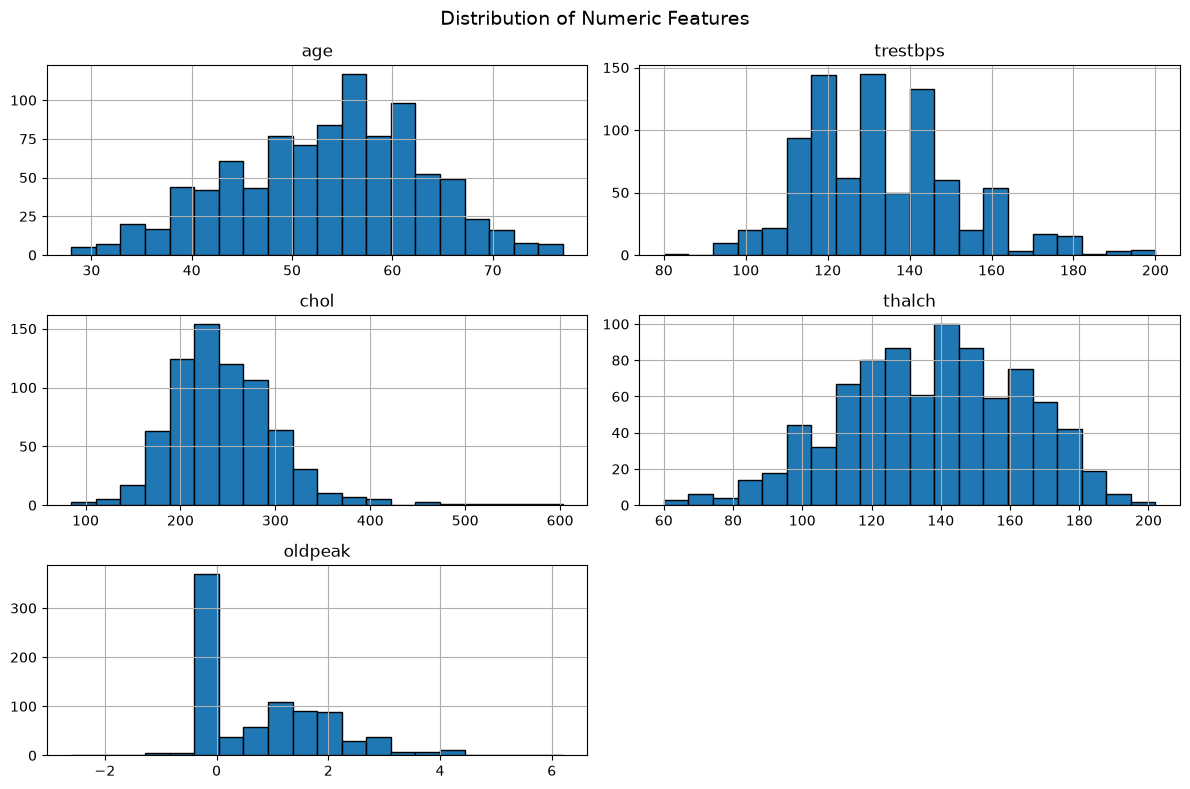

In [2]:
df[numeric_cols].hist(bins=20, figsize=(12, 8), edgecolor="black")
plt.suptitle("Distribution of Numeric Features", fontsize=14)
plt.tight_layout()
plt.savefig("../reports/figures/histograms.png", dpi=150)
plt.show()

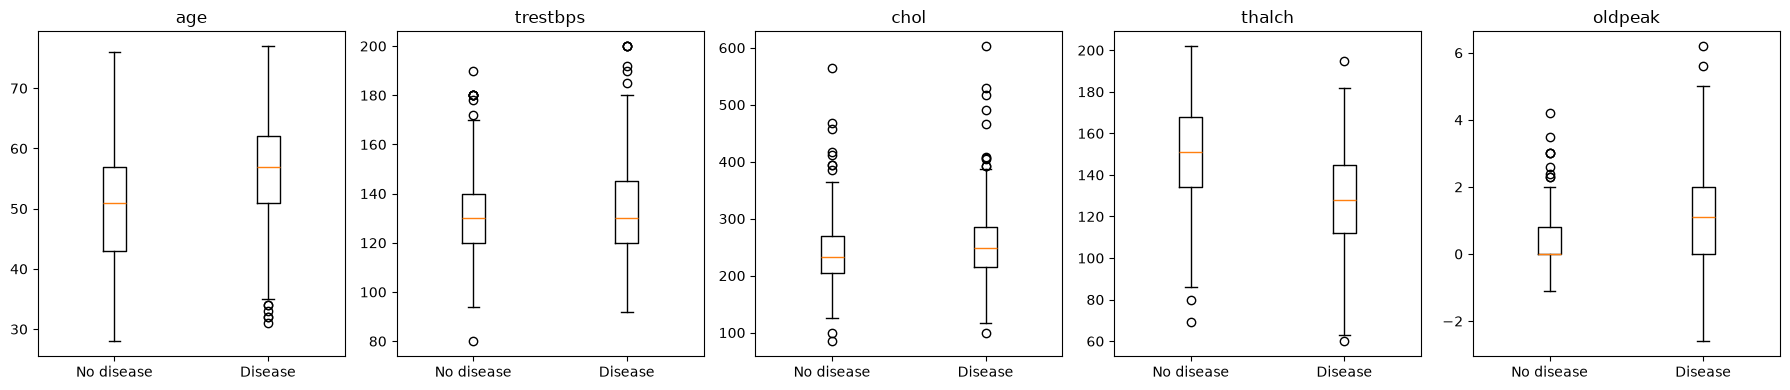

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, col in zip(axes, numeric_cols):
    no_disease = df[df["target"] == 0][col].dropna()
    disease = df[df["target"] == 1][col].dropna()
    ax.boxplot([no_disease, disease], tick_labels=["No disease", "Disease"])
    ax.set_title(col)

plt.tight_layout()
plt.savefig("../reports/figures/boxplots.png", dpi=150)
plt.show()

           age  trestbps  chol  thalch  oldpeak  target
age       1.00      0.25  0.08   -0.37     0.26    0.28
trestbps  0.25      1.00  0.09   -0.10     0.17    0.11
chol      0.08      0.09  1.00   -0.05     0.05    0.12
thalch   -0.37     -0.10 -0.05    1.00    -0.15   -0.39
oldpeak   0.26      0.17  0.05   -0.15     1.00    0.39
target    0.28      0.11  0.12   -0.39     0.39    1.00


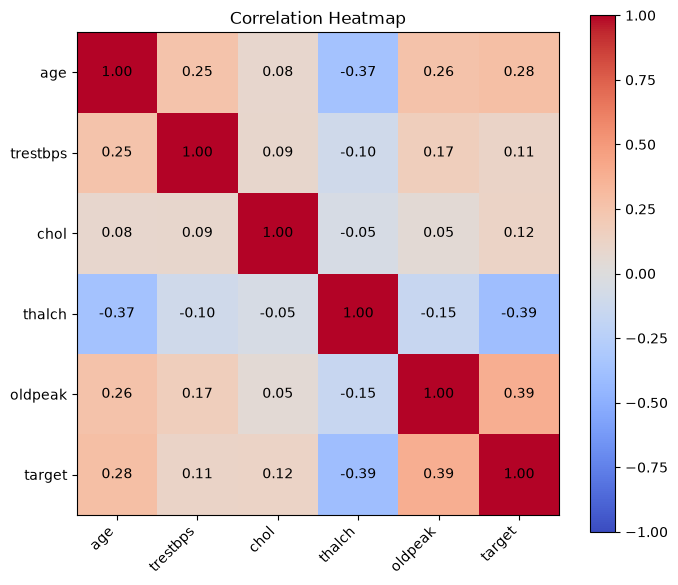

In [4]:
corr_cols = numeric_cols + ["target"]
corr = df[corr_cols].corr()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticklabels(corr_cols)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_heatmap.png", dpi=150)
plt.show()

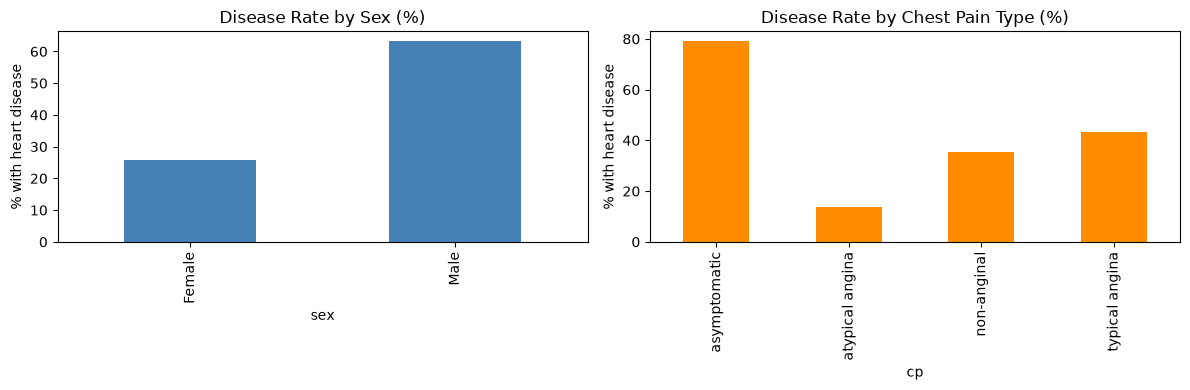

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

(df.groupby("sex")["target"].mean() * 100).plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Disease Rate by Sex (%)")
axes[0].set_ylabel("% with heart disease")

(df.groupby("cp")["target"].mean() * 100).plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Disease Rate by Chest Pain Type (%)")
axes[1].set_ylabel("% with heart disease")

plt.tight_layout()
plt.savefig("../reports/figures/disease_rate_bars.png", dpi=150)
plt.show()